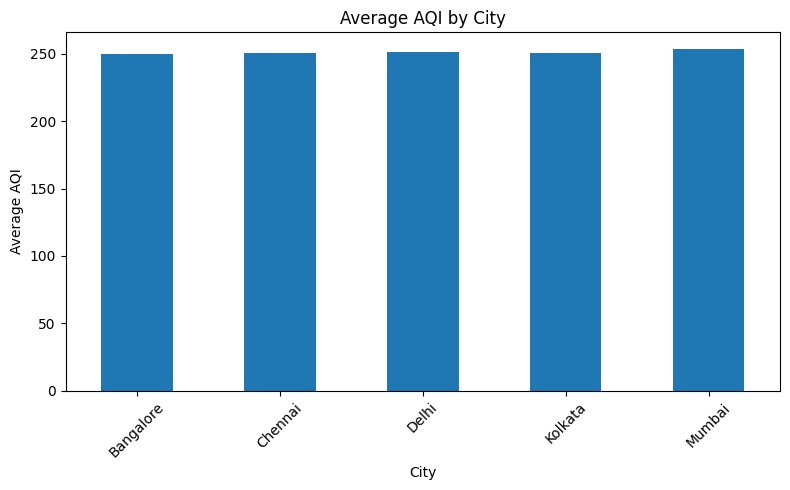

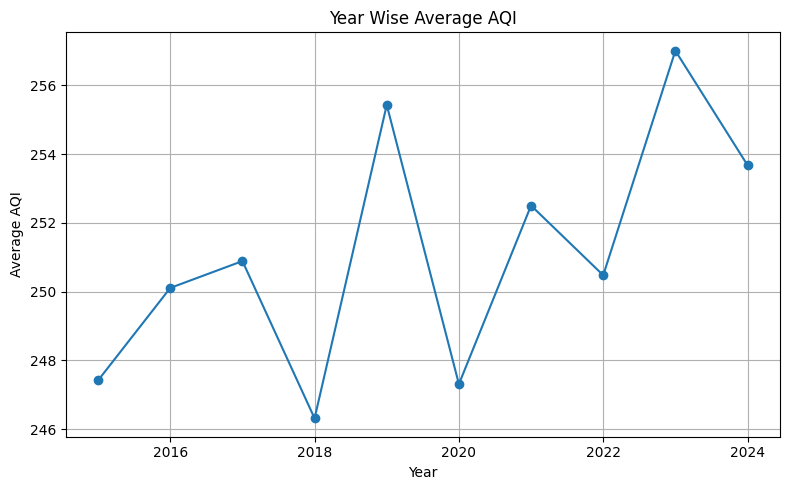

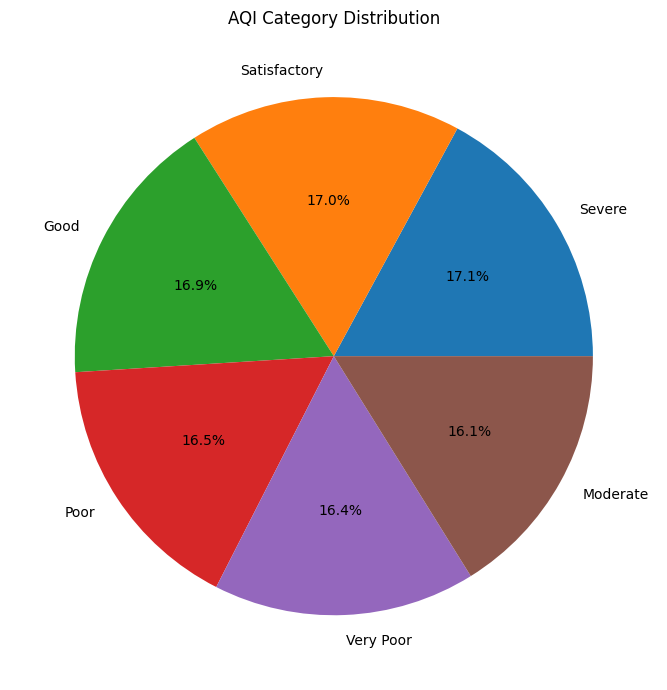

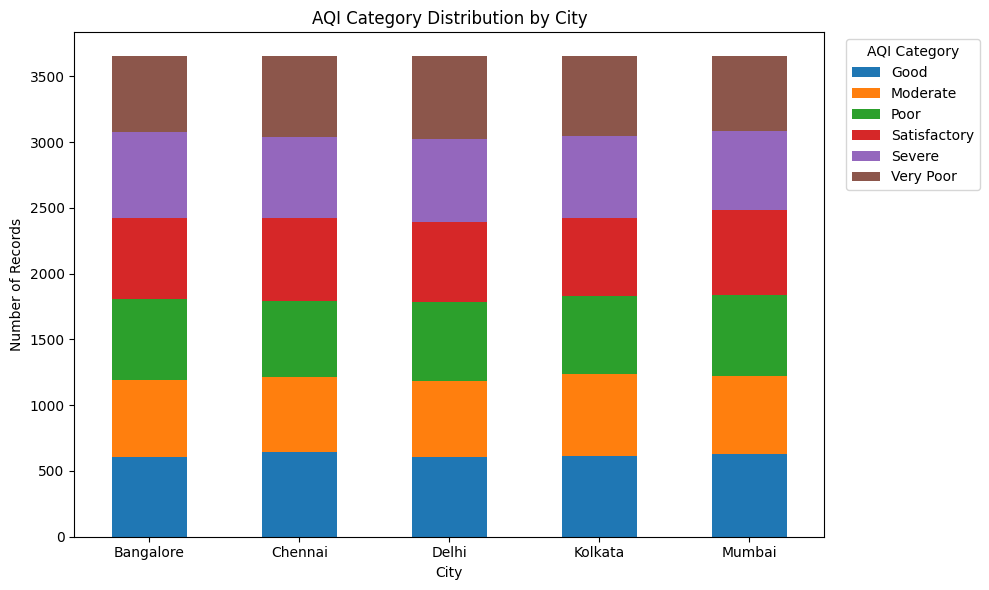

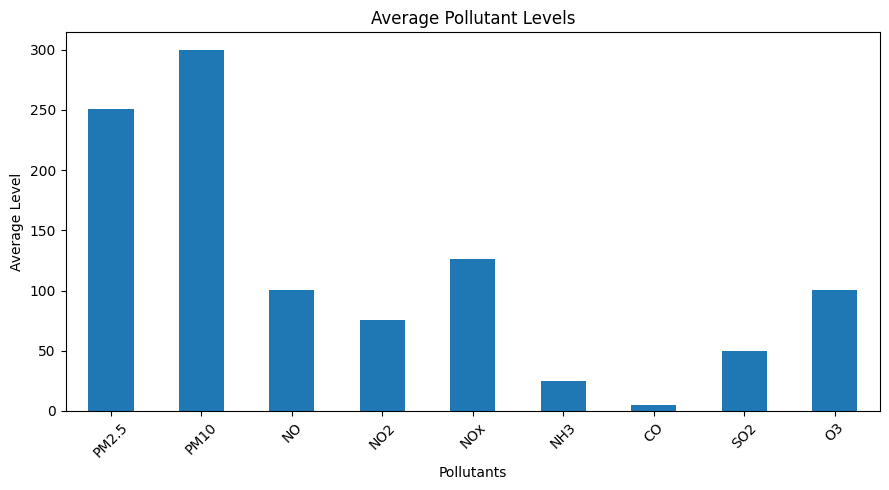

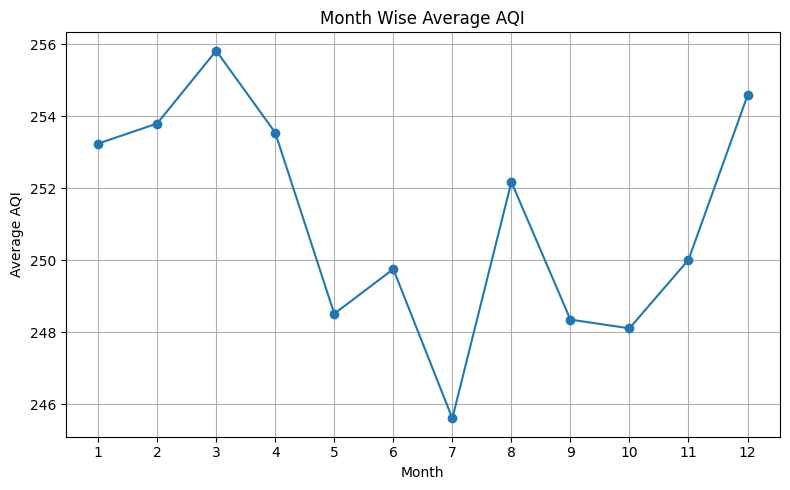

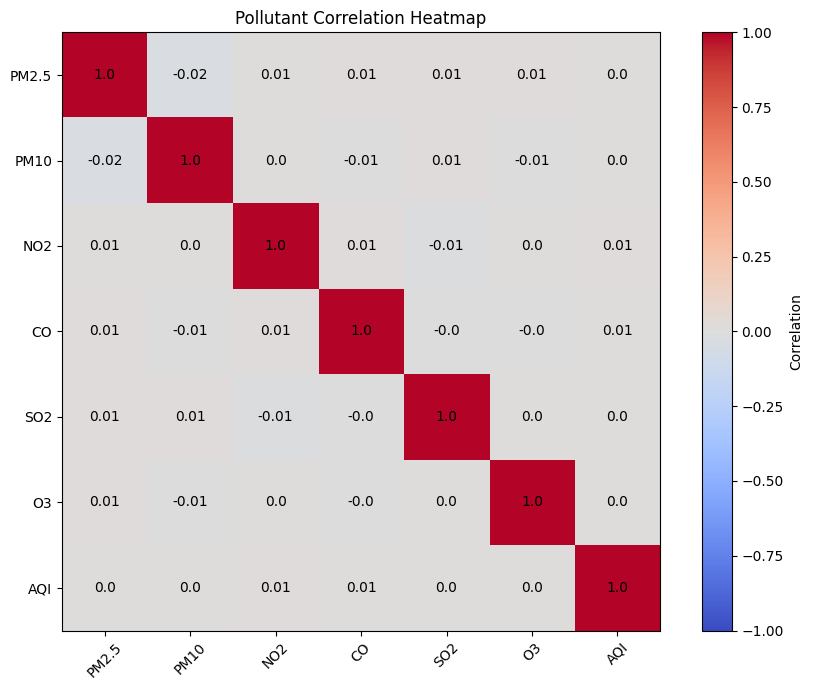

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cleaned_city.csv")

df["Datetime"] = pd.to_datetime(df["Datetime"])

# 1. BAR CHART - Average AQI by City

city_aqi = df.groupby("City")["AQI"].mean()
plt.figure(figsize=(8, 5))
city_aqi.plot(kind="bar")
plt.title("Average AQI by City")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()


# 2. LINE CHART - Year Wise Average AQI

df["Year"] = df["Datetime"].dt.year
year_aqi = df.groupby("Year")["AQI"].mean()
plt.figure(figsize=(8, 5))
year_aqi.plot(kind="line", marker="o")
plt.title("Year Wise Average AQI")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.grid()
plt.tight_layout()
plt.show()
plt.close(fig)


# 3. PIE CHART - AQI Category Distribution

aqi_count = df["AQI_Bucket"].value_counts()

plt.figure(figsize=(7, 7))
aqi_count.plot(kind="pie", autopct="%1.1f%%")

plt.title("AQI Category Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()
plt.close()

# 4. STACKED BAR CHART - AQI Categories by City

aqi_city = pd.crosstab(df["City"], df["AQI_Bucket"])

ax = aqi_city.plot(kind="bar", stacked=True, figsize=(10, 6))

ax.set_title("AQI Category Distribution by City")
ax.set_xlabel("City")
ax.set_ylabel("Number of Records")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="AQI Category", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()
plt.close()


# 5. BAR CHART - Average Pollutant Levels

pollutants = ["PM2.5", "PM10", "NO", "NO2",
              "NOx", "NH3", "CO", "SO2", "O3"]

pollutant_avg = df[pollutants].mean()

plt.figure(figsize=(9, 5))
pollutant_avg.plot(kind="bar")

plt.title("Average Pollutant Levels")
plt.xlabel("Pollutants")
plt.ylabel("Average Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()


# 6. LINE CHART - Month Wise Average AQI

df["Month"] = df["Datetime"].dt.month

month_aqi = df.groupby("Month")["AQI"].mean()

plt.figure(figsize=(8, 5))
month_aqi.plot(kind="line", marker="o")

plt.title("Month Wise Average AQI")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.grid()
plt.tight_layout()
plt.show()

# 7. POLLUTANT CORRELATION HEATMAP

pollutants = ["PM2.5", "PM10", "NO2", "CO",
              "SO2", "O3", "AQI"]

corr = df[pollutants].corr()

fig, ax = plt.subplots(figsize=(9, 7))

img = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(pollutants)))
ax.set_yticks(range(len(pollutants)))

ax.set_xticklabels(pollutants, rotation=45)
ax.set_yticklabels(pollutants)

for i in range(len(pollutants)):
    for j in range(len(pollutants)):
        ax.text(j, i, round(corr.iloc[i, j], 2),
                ha="center", va="center")

plt.colorbar(img, label="Correlation")
ax.set_title("Pollutant Correlation Heatmap")

plt.tight_layout()
plt.show()
plt.close(fig)
